# Tutorial 4: Analyze spatial ATAC-RNA-seq mouse brain dataset

In this tutorial, we demonstrate how to apply Redex to ATAC-seq data.  We use the E13_5-S1 section as an example.

The data should be placed under './ATAC/' in h5ad format.

## Loading packages

In [ ]:
# Installed package imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import torch
from scipy import sparse
from sklearn import metrics
from sklearn.metrics import normalized_mutual_info_score
import method
import Redex
from utils import clustering, find_marker_genes

os.environ['R_HOME'] = '/home/user/anaconda3/envs/redex/lib/R'

## Configuration

In [2]:
DATA_ROOT   = './ATAC'
RESULT_ROOT = './ATAC/result'
FIG_ROOT    = './ATAC/figs'

DATASETS = {
    'E13_5-S1_atac': {'n_clusters': 12, 'gt_key': 'Annotation_for_Combined'},
}


## Load data and Helper functions
To read the ATAC data and perform preprocessing, additional functions are required.


In [3]:
def ensure_sparse_csr(mat):
    """ CSR """
    if isinstance(mat, np.matrix):
        return sparse.csr_matrix(mat)
    if not sparse.issparse(mat):
        return sparse.csr_matrix(mat)
    if mat.format not in ('csr', 'csc'):
        return mat.tocsr()
    return mat


def tfidf_transform(count_mat, scale_factor=1e4, eps=1e-12):
    """
    TF-IDF
    """
    if count_mat.format != 'csr':
        count_mat = count_mat.tocsr()
    # Term Frequency
    row_sums = count_mat.sum(axis=1).A.ravel() + eps
    tf = count_mat.multiply(1.0 / row_sums[:, np.newaxis])
    # Inverse Document Frequency
    n_cells = count_mat.shape[0]
    idf = np.log(1 + n_cells / (1 + (count_mat > 0).sum(axis=0).A1))
    # TF-IDF + log1p
    tf_idf = tf.multiply(idf) * scale_factor
    tf_idf.data = np.log1p(tf_idf.data)
    return tf_idf.tocsr() if tf_idf.format != 'csr' else tf_idf


def load_atac(h5ad_path):
    """ load ATAC h5ad and TF-IDF """
    adata = sc.read_h5ad(h5ad_path)
    adata.X = ensure_sparse_csr(adata.X)
    adata.X = tfidf_transform(adata.X)
    adata.var_names_make_unique()
    print(f"Loaded ATAC: {adata.shape[0]} cells × {adata.shape[1]} peaks")
    return adata
    

## Step 1: Peak Selection (Skip if the peak set already exists.)
Redex performs SVF selection module by computing the R_g score across multiple expression thresholds (25th, 50th, 75th percentiles) and merging the results.
In this Tutorial, we select 3000 SV peaks.

In [5]:
for dataset in DATASETS:
    save_dir = os.path.join(RESULT_ROOT, dataset)
    gene_result_file = os.path.join(save_dir, 'three_top_rg-results_df.csv')

    if os.path.exists(gene_result_file):
        print(f"[Skip] Peak selection for {dataset} — already exists.")
        continue

    print(f"\n{'='*50}")
    print(f"Gene selection for {dataset}")
    print(f"{'='*50}")

    h5ad_path = os.path.join(DATA_ROOT, f'{dataset}.h5ad')
    adata = load_atac(h5ad_path)
    adata = method.preprocess_adata(adata, min_cells=50)
    neighbors = method.compute_neighbors(adata, k_neighbors=6)

    results_dict = {}
    for thre in [25, 50, 75]:
        gene_groups = method.compute_gene_groups(adata, exp_thre=thre, num_workers=1)
        W_gs = method.compute_weight_matrices(adata, neighbors, num_workers=1)
        results, R_g_values = method.compute_r_values(adata, W_gs, num_workers=1)
        results_dict[thre] = results

    results_df = method.merge_files_and_compute_max(results_dict)
    os.makedirs(save_dir, exist_ok=True)
    results_df.to_csv(os.path.join(save_dir, 'three_top_rg-results_df.csv'), index=False)
    print(f"Gene selection results saved to {save_dir}")
    


Gene selection for E13_5-S1_atac
Loaded ATAC: 1777 cells × 271126 peaks


Computing gene groups: 100%|███████████████████████████████████████████████████| 67463/67463 [00:23<00:00, 2888.90it/s]
D:\Users\jtyu\新建文件夹\NEW MODEL WITH NEW GENE COMBINE\github test\method.py:98: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata.var['L_g'] = adata.var.index.map(lambda x: results[x]['L_g'] if x in results else [])
Computing R values: 100%|███████████████████████████████████████████████████████| 67463/67463 [02:13<00:00, 503.72it/s]


 R_g =A_g * B_g * C_g 


Computing R values: 100%|███████████████████████████████████████████████████████| 67463/67463 [02:24<00:00, 467.26it/s]


 R_g =A_g * B_g * C_g 


Computing R values: 100%|███████████████████████████████████████████████████████| 67463/67463 [02:15<00:00, 497.58it/s]


 R_g =A_g * B_g * C_g 
Gene selection results saved to ./ATAC/result\E13_5-S1_atac


## Step 2: Model Training
After peak selection, we train the Redex model using the selected SV peaks.


In [6]:
for dataset, cfg in DATASETS.items():
    n_clusters = cfg['n_clusters']
    gt_key     = cfg['gt_key']

    print(f"\n{'='*50}")
    print(f"Processing {dataset} (n_clusters={n_clusters})")
    print(f"{'='*50}")

    h5ad_path = os.path.join(DATA_ROOT, f'{dataset}.h5ad')
    gene_path = os.path.join(RESULT_ROOT, dataset)
    save_dir  = os.path.join(RESULT_ROOT, dataset)
    os.makedirs(save_dir, exist_ok=True)

    # ------ Load & preprocess ------
    adata = load_atac(h5ad_path)

    # ------ Train model ------
    model = Redex.Redex(adata, dataset, gene_path)
    adata = model.train()



Processing E13_5-S1_atac (n_clusters=12)
Loaded ATAC: 1777 cells × 271126 peaks
 self.alpha 20
  self.beta 6
   self.num_heads 13
processed E13_5-S1_atac our gene 3000
Begin to train ST data...


100%|████████████████████████████████████████████████████████████████████████████████| 700/700 [01:03<00:00, 10.94it/s]

Optimization finished for ST data!


## Step 3: Spatial Clustering
After model training, we apply mclust for spatial clustering with domain refinement.

In [7]:
clustering(adata, n_clusters, radius=1, method='mclust', refinement=True)

R[write to console]:                    __           __ 
   ____ ___  _____/ /_  _______/ /_
  / __ `__ \/ ___/ / / / / ___/ __/
 / / / / / / /__/ / /_/ (__  ) /_  
/_/ /_/ /_/\___/_/\__,_/____/\__/   version 6.0.0
Type 'citation("mclust")' for citing this R package in publications.



fitting ...
  |======================================================================| 100%


## Step 4: Evaluation
We evaluate the clustering performance using Adjusted Rand Index (ARI) and Normalized Mutual Information (NMI) against the manual annotation.


In [8]:
adata.obs['ground_truth'] = adata.obs[gt_key]
adata = adata[~pd.isnull(adata.obs['ground_truth'])]
ari = metrics.adjusted_rand_score(adata.obs['mclust'], adata.obs['ground_truth'])
nmi = normalized_mutual_info_score(adata.obs['mclust'], adata.obs['ground_truth'])
print(f"ARI: {ari:.4f}  |  NMI: {nmi:.4f}")


ARI: 0.3284  |  NMI: 0.5026


## Step 5: Visualization
Spatial domain plot 

D:\Users\jtyu\software\Anaconda\envs\GraphST\lib\site-packages\anndata\_core\anndata.py:1230: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


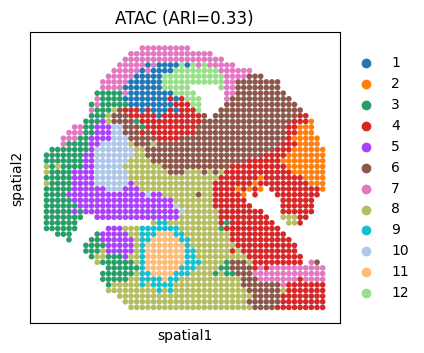

D:\Users\jtyu\software\Anaconda\envs\GraphST\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
D:\Users\jtyu\software\Anaconda\envs\GraphST\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


<Figure size 400x400 with 0 Axes>

<Figure size 400x400 with 0 Axes>

In [9]:
plt.rcParams["figure.figsize"] = (4, 4)
sc.pl.spatial(adata, color='mclust',
                  title=f'ATAC (ARI={ari:.2f})', spot_size=1,
                  save=f'{dataset}_Redex.pdf')

    # ------ UMAP ------
sc.pp.neighbors(adata, use_rep='emb_pca')
sc.tl.umap(adata)
os.makedirs(FIG_ROOT, exist_ok=True)

plt.figure(figsize=(4, 4))
sc.pl.umap(adata, color='mclust', title=f'UMAP - {dataset}',
               frameon=False, size=10, show=False)
plt.savefig(os.path.join(FIG_ROOT, f'{dataset}_UMAP.pdf'), dpi=600, bbox_inches='tight')
plt.close()


    # ------ PAGA ------
sc.tl.paga(adata, groups='mclust')
plt.figure(figsize=(4, 4))
sc.pl.paga(adata, color='mclust', title=f'PAGA - {dataset}',
               frameon=False, show=False)
plt.savefig(os.path.join(FIG_ROOT, f'{dataset}_PAGA.pdf'), dpi=600, bbox_inches='tight')
plt.close()


## Step 6: Find marker peak
Find marker peak for each domain 

In [10]:
marker_dir = os.path.join(save_dir, "marker_peaks")
os.makedirs(marker_dir, exist_ok=True)
find_marker_genes(adata, marker_dir, cluster_key='mclust', quant_in=30, quant_out=70)
print(f"Dataset {dataset} done.")


Marker genes saved to ./ATAC/result\E13_5-S1_atac\marker_peaks
Dataset E13_5-S1_atac done.
